<a href="https://colab.research.google.com/github/pratibha-09-ai/Game/blob/main/Data_Analytics_practice_2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("/content/hotel_bookings.csv")

print("Dataset loaded successfully!")


In [ ]:
df.head()

In [ ]:
df.shape

In [ ]:
df.columns

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87396 entries, 0 to 87395
Data columns (total 34 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           87396 non-null  object        
 1   is_canceled                     87396 non-null  int64         
 2   lead_time                       87396 non-null  int64         
 3   arrival_date_year               87396 non-null  int64         
 4   arrival_date_month              87396 non-null  object        
 5   arrival_date_week_number        87396 non-null  int64         
 6   arrival_date_day_of_month       87396 non-null  int64         
 7   stays_in_weekend_nights         87396 non-null  int64         
 8   stays_in_week_nights            87396 non-null  int64         
 9   adults                          87396 non-null  int64         
 10  children                        87396 non-null  int64         
 11  ba

In [31]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,Total stays,Total guest
count,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,...,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000,87396,87396.000000,87396.000000
mean,0.274898,79.891368,2016.210296,26.838334,15.815541,1.005263,2.625395,1.875795,0.138633,0.010824,...,0.271603,81.004657,11.016809,0.749565,106.337246,0.084226,0.698567,2016-08-31 03:44:08.963339520,3.630658,2.025253
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000,2014-10-17 00:00:00,0.000000,0.000000
25%,0.000000,11.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,...,0.000000,9.000000,0.000000,0.000000,72.000000,0.000000,0.000000,2016-03-18 00:00:00,2.000000,2.000000
50%,0.000000,49.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,...,0.000000,9.000000,0.000000,0.000000,98.100000,0.000000,0.000000,2016-09-08 00:00:00,3.000000,2.000000
75%,1.000000,125.000000,2017.000000,37.000000,23.000000,2.000000,4.000000,2.000000,0.000000,0.000000,...,0.000000,234.000000,0.000000,0.000000,134.000000,0.000000,1.000000,2017-03-05 00:00:00,5.000000,2.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,...,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000,2017-09-14 00:00:00,69.000000,55.000000
std,0.446466,86.052325,0.686102,13.674572,8.835146,1.031921,2.053584,0.626500,0.455871,0.113597,...,0.727245,109.945638,54.047484,10.015731,55.013953,0.281533,0.831946,NaN,2.763449,0.794319


In [ ]:
df.isnull().sum()

In [ ]:
df.duplicated().sum()

In [ ]:
df["country"]=df["country"].fillna("unknown")

In [ ]:
df["agent"]=df["agent"].fillna("0")

In [ ]:
df["company"]=df["company"].fillna("0")

In [ ]:
df["children"]=df["children"].fillna("0")

In [ ]:
df.isnull().sum()

In [ ]:
df["children"]=df["children"].astype(int)
df["agent"]=df["agent"].astype(int)
df["company"]=df["company"].astype(int)


In [ ]:
df[df.duplicated()].head()

In [ ]:
print("total rows",len(df))
print("total duplicate rows",len(df[df.duplicated()]))
print("unique rows",len(df)-len(df[df.duplicated()]))

In [ ]:
df = df.drop_duplicates()
df = df.reset_index(drop=True)

In [ ]:
df.duplicated().sum()

In [ ]:
df.info()

In [ ]:
df['reservation_status_date'] = pd.to_datetime(
    df['reservation_status_date'],
    errors='coerce'
)

Question 1: Har booking mein total kitni nights stay kiya?

In [ ]:
df["Total stays"] = df["stays_in_week_nights"] + df["stays_in_weekend_nights"]
print(df["Total stays"])

Question 2: Har booking mein total guests kitne the?

In [ ]:
df["Total guest"] = df["children"]+df["adults"]+df["babies"]
print(df["Total guest"])

In [ ]:
df[['adr', 'lead_time', 'Total stays']].describe()

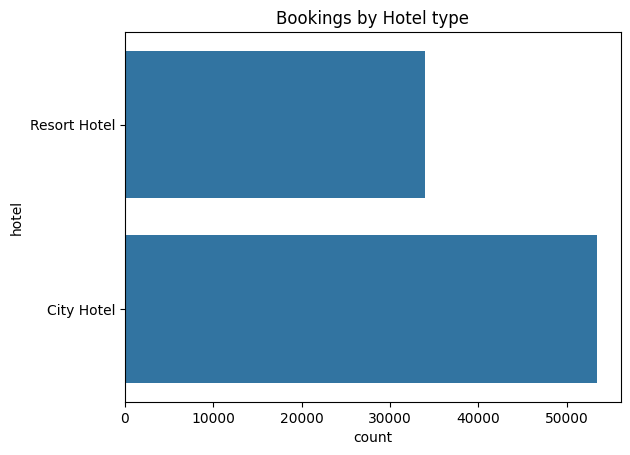

In [30]:
sns.countplot(df['hotel'])
plt.title("Bookings by Hotel type")
plt.show()

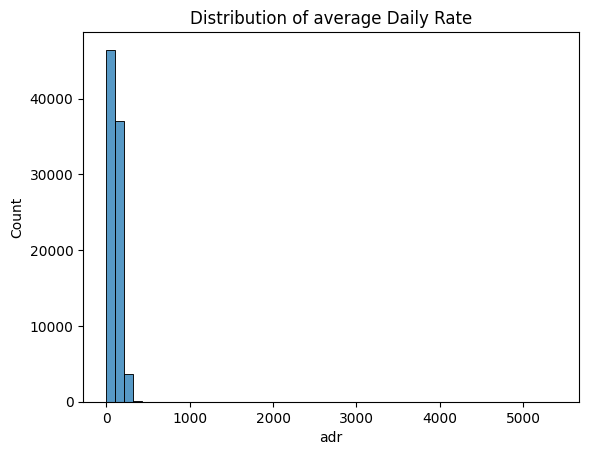

In [29]:
sns.histplot(data = df,x = 'adr',bins = 50)
plt.title('Distribution of average Daily Rate')
plt.show()

In [34]:
df['is_canceled'].value_counts(normalize=True)*100

,proportion
is_canceled,
0,72.510184
1,27.489816


In [35]:
df['arrival_date_month'].value_counts(normalize=True)*100

,proportion
arrival_date_month,
August,12.880452
July,11.507392
May,9.559934
April,9.048469
June,8.884846
March,8.596503
October,7.934002
September,7.654813
February,6.977436


In [36]:
df['market_segment'].value_counts(normalize=True)*100

,proportion
market_segment,
Online TA,59.062200
Offline TA/TO,15.892032
Direct,13.506339
Groups,5.654721
Corporate,4.819443
Complementary,0.803240
Aviation,0.259737
Undefined,0.002288


hotel
City Hotel      30.038557
Resort Hotel    23.480923
Name: is_canceled, dtype: float64


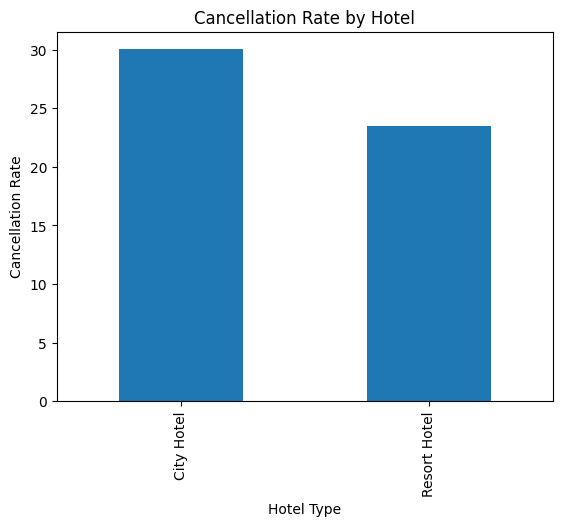

In [41]:
cancellation = df.groupby('hotel')['is_canceled'].mean()*100
print(cancellation)
cancellation.plot(kind='bar')
plt.title('Cancellation Rate by Hotel')
plt.ylabel('Cancellation Rate')
plt.xlabel('Hotel Type')
plt.show()

hotel
City Hotel      110.985944
Resort Hotel     99.025346
Name: adr, dtype: float64


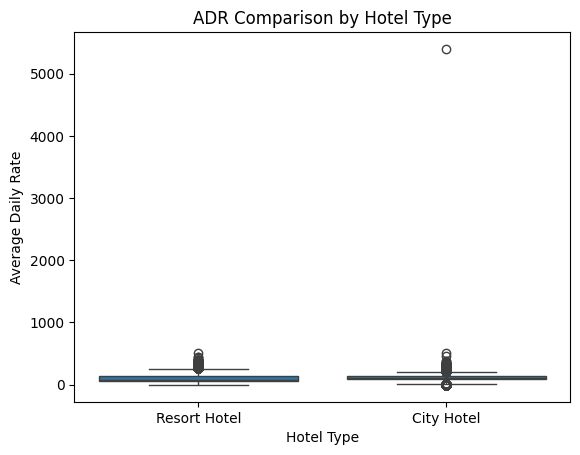

In [42]:

print(df.groupby('hotel')['adr'].mean())

sns.boxplot(data=df, x='hotel', y='adr')
plt.title('ADR Comparison by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Average Daily Rate')
plt.show()


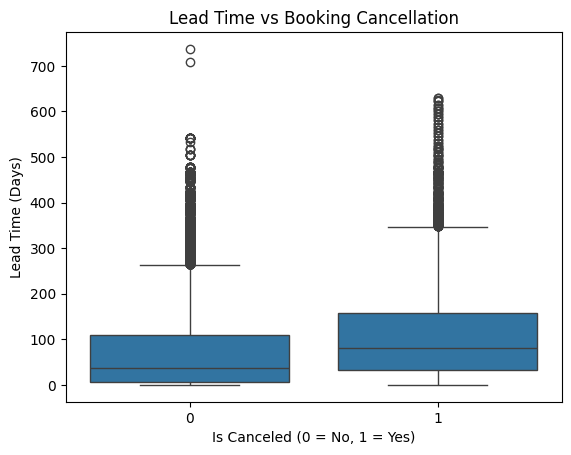

In [43]:
sns.boxplot(data=df, x='is_canceled', y='lead_time')
plt.title('Lead Time vs Booking Cancellation')
plt.xlabel('Is Canceled (0 = No, 1 = Yes)')
plt.ylabel('Lead Time (Days)')
plt.show()


In [44]:

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)


Dataset shape: (87396, 34)

Missing values:
hotel                        0
is_canceled                  0
lead_time                    0
arrival_date_year            0
arrival_date_month           0
arrival_date_week_number     0
arrival_date_day_of_month    0
stays_in_weekend_nights      0
stays_in_week_nights         0
adults                       0
dtype: int64

Duplicate rows: 0

Data types:
hotel                                     object
is_canceled                                int64
lead_time                                  int64
arrival_date_year                          int64
arrival_date_month                        object
arrival_date_week_number                   int64
arrival_date_day_of_month                  int64
stays_in_weekend_nights                    int64
stays_in_week_nights                       int64
adults                                     int64
children                                   int64
babies                                     int64
meal         

## Conclusion — Hotel Booking Data Analysis

In this project, I performed data cleaning, preprocessing, exploratory data analysis (EDA), and data visualization using Python, Pandas, Matplotlib, and Seaborn.

I handled missing values in the country, agent, and company columns and checked duplicate records. I also created new features such as total stay and total guests.

The analysis showed that:
- Online TA was the most common market segment in my results.
- August had the highest number of bookings in my results.
- City Hotel had a higher cancellation rate (30.04%) than Resort Hotel (23.48%).
- City Hotel had a higher average daily rate (ADR).
- Cancelled bookings generally showed a higher lead time than non-cancelled bookings.

This analysis helped me understand how to clean real-world data, identify patterns, visualize results, and draw business insights. These findings can help hotels investigate cancellation patterns and improve booking management.